# Model Training

## Step 0: Import, Directory and Dataset Setup

In [1]:
# Imports
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from catboost import CatBoostClassifier
from sklearn.calibration import CalibratedClassifierCV
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    brier_score_loss,
    f1_score,
    log_loss,
    roc_auc_score,
    roc_curve,
)
from sklearn.model_selection import GridSearchCV, StratifiedKFold
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier

# Directory
ROOT_DIRECTORY = "../dataset/"
CLEANED_DIRECTORY = ROOT_DIRECTORY + "0_cleaned/"
SAVE_DIR = Path("../../ml_engine/saved_models")
TARGET = "is_correct"

# Seed value for reproducibility
RANDOM_STATE = 42

# Dictionary and list to store all generated results
results = {}
models = ["Logistic Regression", "Decision Tree", "CatBoost", "Linear SVM"]
colours = ["#3f665c", "#e56d2f", "#4c72b0", "#c44e52"]

# Function to assist in loading dataset
def load_split(suffix):

    # Retrieve the corresponding dataset based on suffix: tree or distance
    train = pd.read_parquet(f"{CLEANED_DIRECTORY}_train_{suffix}.parquet")
    test = pd.read_parquet(f"{CLEANED_DIRECTORY}_test_{suffix}.parquet")

    # Set the features and target variable for modelling
    X_train = train.drop(columns=[TARGET])
    y_train = train[TARGET].astype(int)
    X_test = test.drop(columns=[TARGET])[X_train.columns]   # identical column order
    y_test = test[TARGET].astype(int)
    return X_train, y_train, X_test, y_test

# Function to show performance metrics after training
def evaluate(model, X_train, y_train, X_test, y_test, name, variant):

    # Retrieve the predicted probabilities
    p_train = model.predict_proba(X_train)[:, 1]
    p_test = model.predict_proba(X_test)[:, 1]

    # Log loss cannot take 0 or 1, so we set a limit for the probabilities
    eps = 1e-15
    p_train_c = np.clip(p_train, eps, 1 - eps)
    p_test_c = np.clip(p_test, eps, 1 - eps)

    # Lastly, we return the metrics for the model
    return {
        "model": name,
        "variant": variant,
        "train_roc_auc": roc_auc_score(y_train, p_train),
        "test_roc_auc": roc_auc_score(y_test, p_test),
        "train_log_loss": log_loss(y_train, p_train_c),
        "test_log_loss": log_loss(y_test, p_test_c),
        "train_brier": brier_score_loss(y_train, p_train),
        "test_brier": brier_score_loss(y_test, p_test),
        "test_accuracy": accuracy_score(y_test, (p_test >= 0.5).astype(int)),
        "test_f1": f1_score(y_test, (p_test >= 0.5).astype(int)),
        "_p_train": p_train,
        "_p_test": p_test,
    }

# Extract the dataset used for tree-based and distance-based model
X_train_tree, y_train_tree, X_test_tree, y_test_tree = load_split("tree")
X_train_dist, y_train_dist, X_test_dist, y_test_dist = load_split("distance")

# Output the details of the training and testing dataset
total_tree = len(X_train_tree) + len(X_test_tree)
print("Tree-encoded dataset:")
print(f"  Train : {len(X_train_tree):>9,} rows x {X_train_tree.shape[1]} features ({len(X_train_tree)/total_tree:.1%})")
print(f"  Test  : {len(X_test_tree):>9,} rows x {X_test_tree.shape[1]} features ({len(X_test_tree)/total_tree:.1%})")

print()
total_dist = len(X_train_dist) + len(X_test_dist)
print("Distance-encoded dataset:")
print(f"  Train : {len(X_train_dist):>9,} rows x {X_train_dist.shape[1]} features ({len(X_train_dist)/total_dist:.1%})")
print(f"  Test  : {len(X_test_dist):>9,} rows x {X_test_dist.shape[1]} features ({len(X_test_dist)/total_dist:.1%})")

Tree-encoded dataset:
  Train : 2,388,519 rows x 21 features (70.0%)
  Test  : 1,023,910 rows x 21 features (30.0%)

Distance-encoded dataset:
  Train : 2,388,519 rows x 21 features (70.0%)
  Test  : 1,023,910 rows x 21 features (30.0%)


## Step 1: Baseline model training

### 1.1 Decision Tree

In [2]:
# Train the decision tree model
decision_tree_base = DecisionTreeClassifier(random_state=RANDOM_STATE)
decision_tree_base.fit(X_train_tree, y_train_tree)

# Record results into dictionary
results[("Decision Tree", "baseline")] = evaluate(
    decision_tree_base, X_train_tree, y_train_tree, X_test_tree, y_test_tree,
    "Decision Tree", "baseline",
)

# Output results
record = results[("Decision Tree", "baseline")]
print(f"Tree depth : {decision_tree_base.get_depth()}\n"
      f"Tree leaves: {decision_tree_base.get_n_leaves():,}\n"
      f"Train ROC-AUC : {record['train_roc_auc']:.4f}   Test ROC-AUC : {record['test_roc_auc']:.4f}\n"
      f"Train log loss: {record['train_log_loss']:.4f}   Test log loss: {record['test_log_loss']:.4f}\n"
      f"Train Brier   : {record['train_brier']:.4f}   Test Brier   : {record['test_brier']:.4f}")

Tree depth : 76
Tree leaves: 519,431
Train ROC-AUC : 1.0000   Test ROC-AUC : 0.5699
Train log loss: 0.0052   Test log loss: 13.3208
Train Brier   : 0.0018   Test Brier   : 0.3862


### 1.2 CatBoost

In [3]:
# Train the CatBoost model
cb_base = CatBoostClassifier(
    random_seed=RANDOM_STATE,
    verbose=0,
)
cb_base.fit(X_train_tree, y_train_tree)

# Save the results to dictionary
results[("CatBoost", "baseline")] = evaluate(
    cb_base, X_train_tree, y_train_tree, X_test_tree, y_test_tree,
    "CatBoost", "baseline",
)

# Output results
record = results[("CatBoost", "baseline")]
print(f"Train ROC-AUC : {record['train_roc_auc']:.4f}   Test ROC-AUC : {record['test_roc_auc']:.4f}\n"
      f"Train log loss: {record['train_log_loss']:.4f}   Test log loss: {record['test_log_loss']:.4f}\n"
      f"Train Brier   : {record['train_brier']:.4f}   Test Brier   : {record['test_brier']:.4f}")

Train ROC-AUC : 0.7661   Test ROC-AUC : 0.7357
Train log loss: 0.5265   Test log loss: 0.5518
Train Brier   : 0.1770   Test Brier   : 0.1871


### 1.3 Logistic Regression

In [4]:
# Train the baseline logistic regression
logistic_regression_base = Pipeline([
    ("scaler", StandardScaler()),
    ("clf", LogisticRegression(random_state=RANDOM_STATE)),
])
logistic_regression_base.fit(X_train_dist, y_train_dist)

# Attach the evaluation results
results[("Logistic Regression", "baseline")] = evaluate(
    logistic_regression_base, X_train_dist, y_train_dist, X_test_dist, y_test_dist,
    "Logistic Regression", "baseline",
)

# Output the results too
record = results[("Logistic Regression", "baseline")]
print(f"Train ROC-AUC : {record['train_roc_auc']:.4f}   Test ROC-AUC : {record['test_roc_auc']:.4f}\n"
      f"Train log loss: {record['train_log_loss']:.4f}   Test log loss: {record['test_log_loss']:.4f}\n"
      f"Train Brier   : {record['train_brier']:.4f}   Test Brier   : {record['test_brier']:.4f}")

Train ROC-AUC : 0.7314   Test ROC-AUC : 0.7119
Train log loss: 0.5559   Test log loss: 0.5697
Train Brier   : 0.1889   Test Brier   : 0.1943


### 1.4 SVM

In [5]:
# Train the baseline SVM (linear SVM)
svm_base = Pipeline([
    ("scaler", StandardScaler()),
    ("svm", CalibratedClassifierCV(
        estimator=LinearSVC(random_state=RANDOM_STATE, dual=False)
    )),
])
svm_base.fit(X_train_dist, y_train_dist)

# Store the results
results[("Linear SVM", "baseline")] = evaluate(
    svm_base, X_train_dist, y_train_dist, X_test_dist, y_test_dist,
    "Linear SVM", "baseline",
)

# Output the results
record = results[("Linear SVM", "baseline")]
print(f"Train ROC-AUC : {record['train_roc_auc']:.4f}   Test ROC-AUC : {record['test_roc_auc']:.4f}\n"
      f"Train log loss: {record['train_log_loss']:.4f}   Test log loss: {record['test_log_loss']:.4f}\n"
      f"Train Brier   : {record['train_brier']:.4f}   Test Brier   : {record['test_brier']:.4f}")

Train ROC-AUC : 0.7314   Test ROC-AUC : 0.7126
Train log loss: 0.5562   Test log loss: 0.5699
Train Brier   : 0.1889   Test Brier   : 0.1942


## Step 2: Hyperparameter tuning

### 2.1 Tuning setup

In [6]:
# Use 5 folds for cross validation
CV = StratifiedKFold(n_splits=5)

# Sample to 500,000 rows to save time
TUNING_SAMPLE_SIZE = 500_000

# A function to perform sampling
def subsample(X, y, n=TUNING_SAMPLE_SIZE, seed=RANDOM_STATE):

    # Return the dataset if the size is already smaller than sample size
    if len(X) <= n: return X, y

    # Perform stratified sampling (preserve class distribution)
    rng = np.random.default_rng(seed)
    idx = np.concatenate([rng.choice(np.flatnonzero(y.to_numpy() == cls), size=int(round(n * (y == cls).mean())), replace=False) for cls in (0, 1)])
    rng.shuffle(idx)
    return X.iloc[idx], y.iloc[idx]

# A function to perform tuning
def tune(estimator, grid, X, y, label):

    # Perform fine-tuning using grid search
    search = GridSearchCV(estimator=estimator,
                          param_grid=grid,
                          scoring={"neg_log_loss": "neg_log_loss",
                                   "roc_auc": "roc_auc",
                                   "neg_brier_score": "neg_brier_score"},
                          refit="neg_log_loss",   # still selects best params by log loss
                          cv=CV,
                          n_jobs=10,
                          verbose=0)
    search.fit(X, y)

    # Output the best parameters and metric
    print(f"----- Tuning for: {label} -----")
    print(f"best params : {search.best_params_}")
    print(f"best CV log loss : {-search.best_score_:.4f}")
    print(f"best CV ROC-AUC  : {search.cv_results_['mean_test_roc_auc'][search.best_index_]:.4f}")
    print(f"best CV Brier    : {-search.cv_results_['mean_test_neg_brier_score'][search.best_index_]:.4f}")

    # Show the top 5 best configurations from the search
    pd.set_option('display.max_colwidth', None)
    top = (pd.DataFrame(search.cv_results_).sort_values("rank_test_neg_log_loss")
                                           .head(5)[["params", "mean_test_neg_log_loss", "mean_test_roc_auc", "mean_test_neg_brier_score"]]
                                           .assign(mean_log_loss=lambda d: -d["mean_test_neg_log_loss"],
                                                   mean_roc_auc =lambda d:  d["mean_test_roc_auc"],
                                                   mean_brier   =lambda d: -d["mean_test_neg_brier_score"])
                                           .drop(columns=["mean_test_neg_log_loss", "mean_test_roc_auc", "mean_test_neg_brier_score"]))
    display(top.round(5))
    return search.best_params_

# Perform stratified sampling on both tree and distance datasets
X_tune_tree, y_tune_tree = subsample(X_train_tree, y_train_tree)
X_tune_dist, y_tune_dist = subsample(X_train_dist, y_train_dist)

# Output the details of stratified training dataset
print(f"Tuning subsample: {len(X_tune_tree):,} rows "
      f"({len(X_tune_tree) / len(X_train_tree):.1%} of train)")
print(f"Class balance: full dataset: {y_train_tree.mean():.4f}  vs  sampled dataset: {y_tune_tree.mean():.4f}")

Tuning subsample: 500,000 rows (20.9% of train)
Class balance: full dataset: 0.6720  vs  sampled dataset: 0.6720


### 2.2 Decision Tree Tuning

In [49]:
dt_grid = {
    "max_depth": [4, 6, 8, 12, 20, 30],
    "min_samples_leaf": [1, 20, 100, 500, 2000],
    "criterion": ["gini", "entropy"],
    "class_weight": [None, "balanced"],
}

dt_best = tune(
    DecisionTreeClassifier(random_state=RANDOM_STATE),
    dt_grid, X_tune_tree, y_tune_tree, "Decision Tree",
)

Exception ignored in: <function ResourceTracker.__del__ at 0x10726a0c0>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 77, in __del__
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 86, in _stop
  File "/Library/Frameworks/Python.framework/Versions/3.12/lib/python3.12/multiprocessing/resource_tracker.py", line 111, in _stop_locked
ChildProcessError: [Errno 10] No child processes
/Users/limbengrhui/Documents/PyCharm/FYP/.venv/lib/python3.12/site-packages/joblib/externals/loky/process_executor.py:752: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(
Exception ignored in: <function ResourceTracker.__del__ at 0x10b8f60c0>
Traceback (most recent call last):
  File "/Library/Frameworks/Python.framework/Versions

----- Tuning for: Decision Tree -----
best params : {'class_weight': None, 'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 500}
best CV log loss : 0.5475
best CV ROC-AUC  : 0.7405
best CV Brier    : 0.1854


,params,mean_log_loss,mean_roc_auc,mean_brier
58,"{'class_weight': None, 'criterion': 'entropy', 'max_depth': 30, 'min_samples_leaf': 500}",0.54749,0.74046,0.18539
53,"{'class_weight': None, 'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 500}",0.54749,0.74046,0.18539
48,"{'class_weight': None, 'criterion': 'entropy', 'max_depth': 12, 'min_samples_leaf': 500}",0.54763,0.74034,0.18546
28,"{'class_weight': None, 'criterion': 'gini', 'max_depth': 30, 'min_samples_leaf': 500}",0.54766,0.74040,0.18533
23,"{'class_weight': None, 'criterion': 'gini', 'max_depth': 20, 'min_samples_leaf': 500}",0.54766,0.74040,0.18533


### 2.3 CatBoost Tuning

In [34]:
cb_grid = {
    "depth": [4, 6, 8, 10],
    "learning_rate": [0.03, 0.05, 0.1],
    "l2_leaf_reg": [1, 3, 5],
}

cb_best = tune(
    CatBoostClassifier(iterations=300,
                       random_seed=RANDOM_STATE,
                       verbose=0,
                       thread_count=1,      # To prevent CatBoost from competing with grid search
    ),
    cb_grid, X_tune_tree, y_tune_tree, "CatBoost",
)

----- Tuning for: CatBoost -----
best params : {'depth': 10, 'l2_leaf_reg': 5, 'learning_rate': 0.05}
best CV log loss : 0.5361
best CV ROC-AUC  : 0.7544
best CV Brier    : 0.1809


,params,mean_log_loss,mean_roc_auc,mean_brier
34,"{'depth': 10, 'l2_leaf_reg': 5, 'learning_rate': 0.05}",0.53607,0.75442,0.18088
31,"{'depth': 10, 'l2_leaf_reg': 3, 'learning_rate': 0.05}",0.53615,0.75431,0.18092
28,"{'depth': 10, 'l2_leaf_reg': 1, 'learning_rate': 0.05}",0.53622,0.75426,0.18093
26,"{'depth': 8, 'l2_leaf_reg': 5, 'learning_rate': 0.1}",0.53626,0.75407,0.18099
23,"{'depth': 8, 'l2_leaf_reg': 3, 'learning_rate': 0.1}",0.53636,0.75399,0.18102


### 2.4 Logistic Regression Tuning

In [33]:
lr_grid = [
    {
        "clf__solver": ["lbfgs"],
        "clf__penalty": ["l2"],
        "clf__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
        "clf__class_weight": [None, "balanced"],
    },
    {
        "clf__solver": ["saga"],
        "clf__penalty": ["l1"],
        "clf__C": [0.001, 0.01, 0.1, 1.0, 10.0, 100.0],
        "clf__class_weight": [None, "balanced"],
    },
]

lr_best = tune(
    Pipeline([("scaler", StandardScaler()),
              ("clf", LogisticRegression(random_state=RANDOM_STATE))]),
    lr_grid, X_tune_dist, y_tune_dist, "Logistic Regression",
)

----- Tuning for: Logistic Regression -----
best params : {'clf__C': 100.0, 'clf__class_weight': None, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}
best CV log loss : 0.5564
best CV ROC-AUC  : 0.7304
best CV Brier    : 0.1891


,params,mean_log_loss,mean_roc_auc,mean_brier
10,"{'clf__C': 100.0, 'clf__class_weight': None, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}",0.55644,0.73043,0.18912
8,"{'clf__C': 10.0, 'clf__class_weight': None, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}",0.55644,0.73043,0.18912
6,"{'clf__C': 1.0, 'clf__class_weight': None, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}",0.55644,0.73043,0.18912
4,"{'clf__C': 0.1, 'clf__class_weight': None, 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}",0.55644,0.73043,0.18912
20,"{'clf__C': 10.0, 'clf__class_weight': None, 'clf__penalty': 'l1', 'clf__solver': 'saga'}",0.55644,0.73043,0.18912


### 2.5 SVM Tuning

In [32]:
svm_grid = {
    "svm__estimator__C": [0.01, 0.1, 1, 10],
}

svm_best = tune(
    Pipeline([("scaler", StandardScaler()),
              ("svm", CalibratedClassifierCV(estimator=LinearSVC(random_state=RANDOM_STATE, dual=False)))
              ]),
    svm_grid, X_tune_dist, y_tune_dist, "Linear SVM",
)

----- Tuning for: Linear SVM -----
best params : {'svm__estimator__C': 10}
best CV log loss : 0.5567
best CV ROC-AUC  : 0.7305
best CV Brier    : 0.1892


,params,mean_log_loss,mean_roc_auc,mean_brier
3,{'svm__estimator__C': 10},0.55673,0.73046,0.18920
2,{'svm__estimator__C': 1},0.55673,0.73046,0.18920
1,{'svm__estimator__C': 0.1},0.55673,0.73046,0.18920
0,{'svm__estimator__C': 0.01},0.55673,0.73046,0.18921


## Step 3: Train fine-tuned models

In [16]:
# Retrain decision tree
dt_tuned = DecisionTreeClassifier(random_state=RANDOM_STATE, **dt_best)
dt_tuned.fit(X_train_tree, y_train_tree)
results[("Decision Tree", "fine-tuned")] = evaluate(                    # Store results
    dt_tuned, X_train_tree, y_train_tree, X_test_tree, y_test_tree, "Decision Tree", "fine-tuned",
)

# Retrain CatBoost
X_fit, X_stop, y_fit, y_stop = train_test_split(                        # An additional split to prevent data leakage
    X_train_tree, y_train_tree, test_size=0.1,
    stratify=y_train_tree, random_state=RANDOM_STATE,
)
cb_tuned = CatBoostClassifier(iterations=1500,       random_seed=RANDOM_STATE,
                              eval_metric="Logloss", early_stopping_rounds=20,
                              verbose=False,         **cb_best,
)
cb_tuned.fit(X_fit, y_fit, eval_set=(X_stop, y_stop), use_best_model=True)
results[("CatBoost", "fine-tuned")] = evaluate(                        # Store results
    cb_tuned, X_train_tree, y_train_tree, X_test_tree, y_test_tree, "CatBoost", "fine-tuned",
)

# Retrain logistic regression
lr_tuned = Pipeline([("scaler", StandardScaler()),
                     ("clf", LogisticRegression(random_state=RANDOM_STATE)),
])
lr_tuned.set_params(**lr_best)
lr_tuned.fit(X_train_dist, y_train_dist)
results[("Logistic Regression", "fine-tuned")] = evaluate(              # Store results
    lr_tuned, X_train_dist, y_train_dist, X_test_dist, y_test_dist, "Logistic Regression", "fine-tuned",
)

# Retrain SVM
svm_tuned = Pipeline([("scaler", StandardScaler()),
                      ("svm", CalibratedClassifierCV(estimator=LinearSVC(random_state=RANDOM_STATE, dual=False))),
])
svm_tuned.set_params(**svm_best)
svm_tuned.fit(X_train_dist, y_train_dist)
results[("Linear SVM", "fine-tuned")] = evaluate(                       # Store results
    svm_tuned, X_train_dist, y_train_dist, X_test_dist, y_test_dist, "Linear SVM", "fine-tuned",
)

# Output applied hyperparameters for each model
lr_applied = lr_tuned.named_steps["clf"].get_params()
svm_applied = {"C": svm_tuned.named_steps["svm"].estimator.C}

print("Applied Hyperparameters:")
print(f"Decision Tree       : {dt_best}")
print(f"CatBoost            : {cb_best}")
print(f"Logistic Regression : { {k: lr_applied[k] for k in ['C', 'penalty', 'solver', 'class_weight']} }")
print(f"SVM                 : {svm_applied}")

Applied Hyperparameters:
Decision Tree       : {'class_weight': None, 'criterion': 'entropy', 'max_depth': 20, 'min_samples_leaf': 500}
CatBoost            : {'depth': 10, 'l2_leaf_reg': 5, 'learning_rate': 0.05}
Logistic Regression : {'C': 100.0, 'penalty': 'l2', 'solver': 'lbfgs', 'class_weight': None}
SVM                 : {'C': 10}


## Step 4: Model Evaluation

### 4.1 Compare training and testing (after hyperparameter tuning)

#### Decision Tree

In [17]:
record = results[("Decision Tree", "fine-tuned")]

print(f"Train ROC-AUC : {record['train_roc_auc']:.4f}   Test ROC-AUC : {record['test_roc_auc']:.4f}")
print(f"Train Log-Loss: {record['train_log_loss']:.4f}   Test Log-Loss: {record['test_log_loss']:.4f}")
print(f"Train Brier   : {record['train_brier']:.4f}   Test Brier   : {record['test_brier']:.4f}")

Train ROC-AUC : 0.7568   Test ROC-AUC : 0.7288
Train Log-Loss: 0.5342   Test Log-Loss: 0.5570
Train Brier   : 0.1803   Test Brier   : 0.1891


#### CatBoost

In [18]:
record = results[("CatBoost", "fine-tuned")]

print(f"Train ROC-AUC : {record['train_roc_auc']:.4f}   Test ROC-AUC : {record['test_roc_auc']:.4f}")
print(f"Train Log-Loss: {record['train_log_loss']:.4f}   Test Log-Loss: {record['test_log_loss']:.4f}")
print(f"Train Brier   : {record['train_brier']:.4f}   Test Brier   : {record['test_brier']:.4f}")

Train ROC-AUC : 0.7683   Test ROC-AUC : 0.7410
Train Log-Loss: 0.5248   Test Log-Loss: 0.5473
Train Brier   : 0.1763   Test Brier   : 0.1854


#### Logistic Regression

In [19]:
record = results[("Logistic Regression", "fine-tuned")]

print(f"Train ROC-AUC : {record['train_roc_auc']:.4f}   Test ROC-AUC : {record['test_roc_auc']:.4f}")
print(f"Train Log-Loss: {record['train_log_loss']:.4f}   Test Log-Loss: {record['test_log_loss']:.4f}")
print(f"Train Brier   : {record['train_brier']:.4f}   Test Brier   : {record['test_brier']:.4f}")

Train ROC-AUC : 0.7314   Test ROC-AUC : 0.7119
Train Log-Loss: 0.5559   Test Log-Loss: 0.5697
Train Brier   : 0.1889   Test Brier   : 0.1943


#### SVM

In [20]:
record = results[("Linear SVM", "fine-tuned")]

print(f"Train ROC-AUC : {record['train_roc_auc']:.4f}   Test ROC-AUC : {record['test_roc_auc']:.4f}")
print(f"Train Log-Loss: {record['train_log_loss']:.4f}   Test Log-Loss: {record['test_log_loss']:.4f}")
print(f"Train Brier   : {record['train_brier']:.4f}   Test Brier   : {record['test_brier']:.4f}")

Train ROC-AUC : 0.7314   Test ROC-AUC : 0.7126
Train Log-Loss: 0.5562   Test Log-Loss: 0.5699
Train Brier   : 0.1889   Test Brier   : 0.1942


### 4.2 Compare baseline and fine-tuned models

In [43]:
# Generate the table to compare between baseline and fine-tuned models
deltas = []
for name in ["Logistic Regression", "Decision Tree", "CatBoost", "Linear SVM"]:
    base, tuned = results[(name, "baseline")], results[(name, "fine-tuned")]
    deltas.append({
        "model": name,
        "ROC-AUC (base)": base["test_roc_auc"],
        "ROC-AUC (tuned)": tuned["test_roc_auc"],
        "Δ ROC-AUC": tuned["test_roc_auc"] - base["test_roc_auc"],
        "Log loss (base)": base["test_log_loss"],
        "Log loss (tuned)": tuned["test_log_loss"],
        "Δ Log loss": tuned["test_log_loss"] - base["test_log_loss"],
        "Brier (base)": base["test_brier"],
        "Brier (tuned)": tuned["test_brier"],
        "Δ Brier": tuned["test_brier"] - base["test_brier"],
    })
delta_table = pd.DataFrame(deltas)
display(delta_table.round(4))

,model,ROC-AUC (base),ROC-AUC (tuned),Δ ROC-AUC,Log loss (base),Log loss (tuned),Δ Log loss,Brier (base),Brier (tuned),Δ Brier
0,Logistic Regression,0.7119,0.7119,-0.0000,0.5697,0.5697,0.0000,0.1943,0.1943,0.0000
1,Decision Tree,0.5699,0.7288,0.1589,13.3208,0.5570,-12.7638,0.3862,0.1891,-0.1972
2,CatBoost,0.7357,0.7410,0.0052,0.5518,0.5473,-0.0045,0.1871,0.1854,-0.0017
3,Linear SVM,0.7126,0.7126,-0.0000,0.5699,0.5699,0.0000,0.1942,0.1942,0.0000


### 4.3 ROC-AUC curves

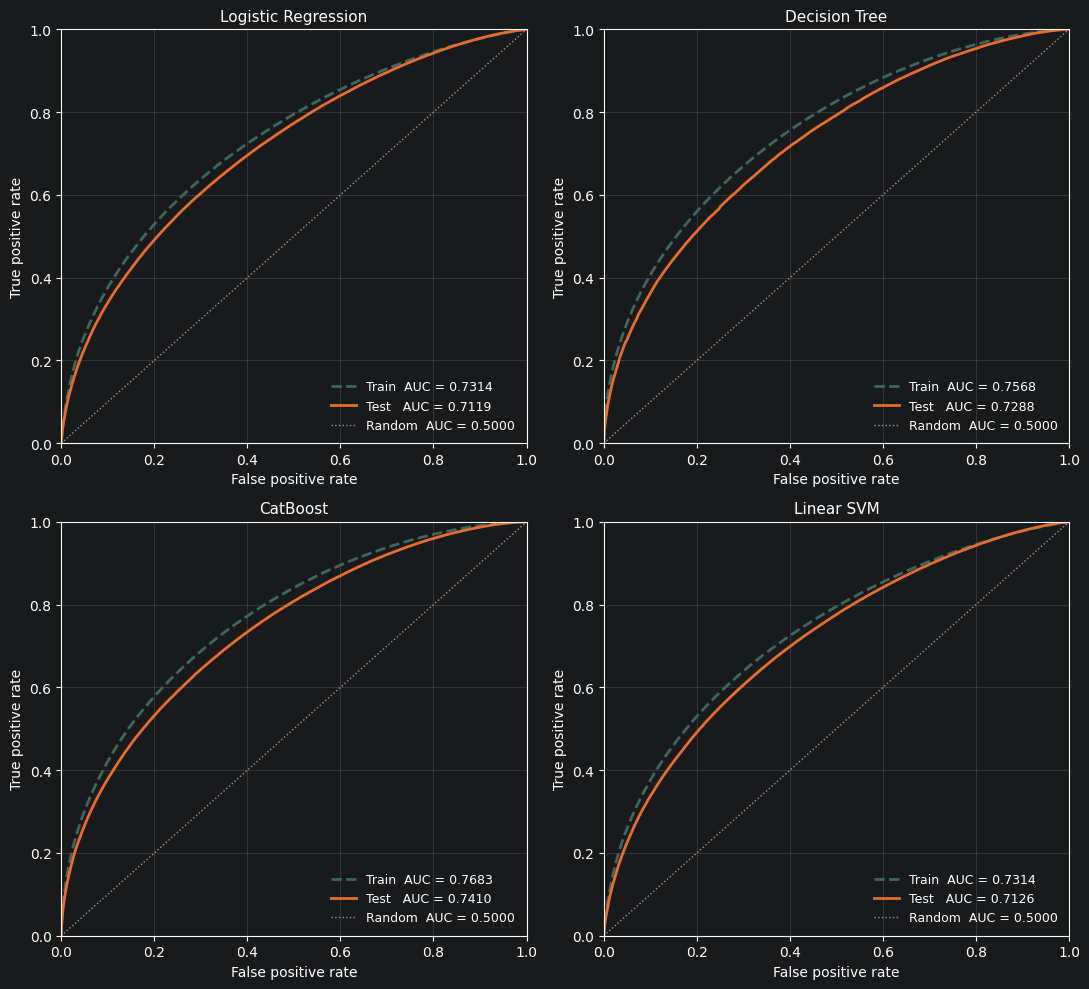

In [45]:
# Create a 2x2 grid for ROC curve
fig, axes = plt.subplots(2, 2, figsize=(11, 10))
axes = axes.flatten()

for ax, name in zip(axes, models):

    # Extract the record for each fine-tuned model
    record = results[(name, "fine-tuned")]

    # Generate ROC curve
    fpr_tr, tpr_tr, _ = roc_curve(y_train_tree, record["_p_train"])
    fpr_te, tpr_te, _ = roc_curve(y_test_tree, record["_p_test"])
    auc_tr, auc_te = record["train_roc_auc"], record["test_roc_auc"]

    # Legend
    ax.plot(fpr_tr, tpr_tr, "--", color="#3f665c", lw=2, label=f"Train  AUC = {auc_tr:.4f}")
    ax.plot(fpr_te, tpr_te, "-", color="#e56d2f", lw=2, label=f"Test   AUC = {auc_te:.4f}")
    ax.plot([0, 1], [0, 1], ":", color="#999", lw=1, label="Random  AUC = 0.5000")

    # Generate the curve
    ax.set_title(name, fontsize=11)
    ax.set_xlabel("False positive rate")
    ax.set_ylabel("True positive rate")
    ax.legend(loc="lower right", frameon=False, fontsize=9)
    ax.grid(alpha=0.25)
    ax.set_axisbelow(True)
    ax.set_xlim(0, 1); ax.set_ylim(0, 1)

# Plot the curve
fig.tight_layout()
plt.show()

### 4.4 Calibration curves

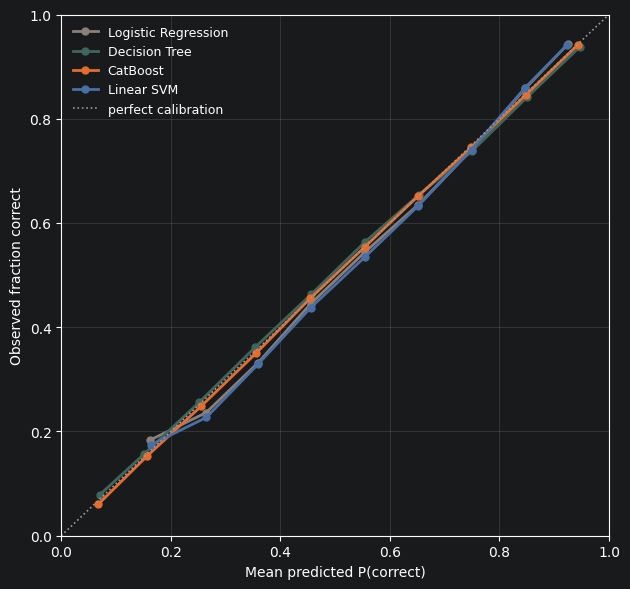

In [46]:
# Generate the grid for calibration curve
fig, ax = plt.subplots(figsize=(6.4, 6))
bins = np.linspace(0, 1, 11)

# Loop through each fine-tuned ML model
for name, colour in zip(models, colours):

    # Retrieve their predicted probabilites
    p = results[(name, "fine-tuned")]["_p_test"]
    idx = np.digitize(p, bins) - 1
    idx = np.clip(idx, 0, len(bins) - 2)

    # Bin probabilities and generate the curve
    xs, ys = [], []
    for b in range(len(bins) - 1):
        mask = idx == b
        if mask.sum() >= 500:          # ignore bins too sparse to read
            xs.append(p[mask].mean())
            ys.append(y_test_tree.to_numpy()[mask].mean())
    ax.plot(xs, ys, "o-", color=colour, lw=2, ms=5, label=name)

# Plot the curve
ax.plot([0, 1], [0, 1], ":", color="#999", lw=1.2, label="perfect calibration")
ax.set_xlabel("Mean predicted P(correct)")
ax.set_ylabel("Observed fraction correct")
ax.legend(frameon=False, fontsize=9, loc="upper left")
ax.grid(alpha=0.25); ax.set_axisbelow(True)
ax.set_xlim(0, 1); ax.set_ylim(0, 1)
fig.tight_layout()

## Step 5: Champion model selection

### 5.1 Feature Importance

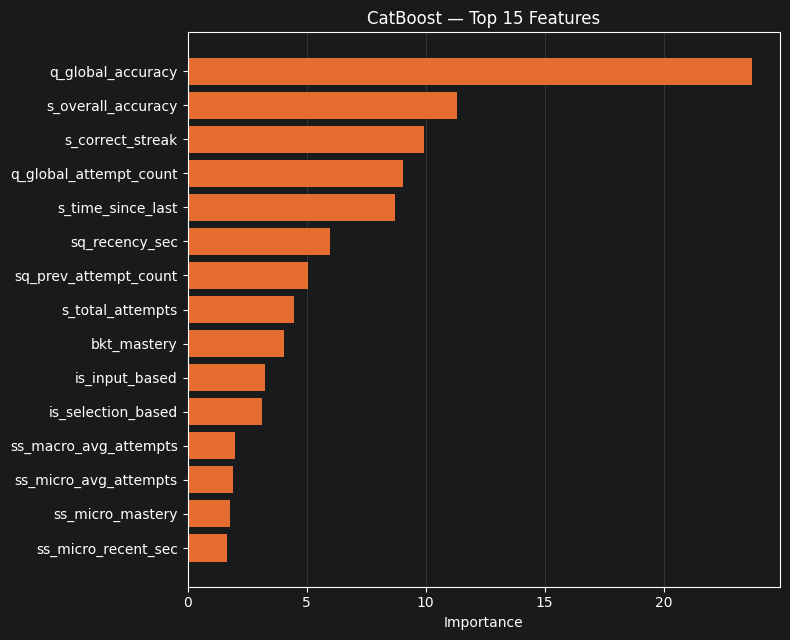

In [47]:
# Retrieve the columns and rank its importance in CatBoost
FEATURE_ORDER = list(X_train_tree.columns)
importance = cb_tuned.get_feature_importance()
imp = (
    pd.DataFrame({"feature": FEATURE_ORDER, "importance": importance})
    .sort_values("importance", ascending=False)
    .head(15)
    .iloc[::-1]
)

# Plot the bar chart
fig, ax = plt.subplots(figsize=(8, 6.5))
ax.barh(imp["feature"], imp["importance"], color="#e56d2f")
ax.set_title("CatBoost — Top 15 Features", fontsize=12)
ax.set_xlabel("Importance")
ax.grid(axis="x", alpha=0.25); ax.set_axisbelow(True)
fig.tight_layout()
plt.show()

### 5.2 Champion model export

In [50]:
# Define the path to store the champion model with its features
model_path = SAVE_DIR / "champion_catboost.cbm"
order_path = SAVE_DIR / "feature_order.json"

# Save the champion model and feature order to disk
cb_tuned.save_model(str(model_path))
order_path.write_text(json.dumps(FEATURE_ORDER, indent=2))

# Output result
print("Model and feature order are saved to disk.")

# A quick test to try reload the model and verify if everything works
reloaded = CatBoostClassifier()
reloaded.load_model(str(model_path))

# Check features
loaded_order = json.loads(order_path.read_text())
assert loaded_order == FEATURE_ORDER, "feature_order.json does not match"

# Check performance metrics
p_reloaded = reloaded.predict_proba(X_test_tree[loaded_order])[:, 1]
auc_reloaded = roc_auc_score(y_test_tree, p_reloaded)
test_auc = results[("CatBoost", "fine-tuned")]["test_roc_auc"]
assert np.isclose(auc_reloaded, test_auc), "export did not round-trip"

# Output success message
print("Successfully reloaded the champion model and verified its performance.")

Model and feature order are saved to disk.
Successfully reloaded the champion model and verified its performance.
